<a href="https://colab.research.google.com/github/bonobobit/qff2026/blob/main/string_matching.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

A quantum algorithm for string matching.
Implementazione dell'algoritmo descritto in
Niroula, P., Nam, Y. A quantum algorithm for string matching. npj Quantum Inf 7, 37 (2021). https://doi.org/10.1038/s41534-021-00369-3

In [2]:
%pip install qiskit pylatexenc numpy qiskit_aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 84.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 106.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 80.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [qiskit_aer]


In [22]:
from qiskit import QuantumRegister, QuantumCircuit, ClassicalRegister, transpile
import numpy as np
from qiskit.circuit.library import QFTGate
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

Conteggi: {'101': 61, '001': 68, '110': 75, '111': 69, '011': 69, '100': 330, '010': 61, '000': 291}


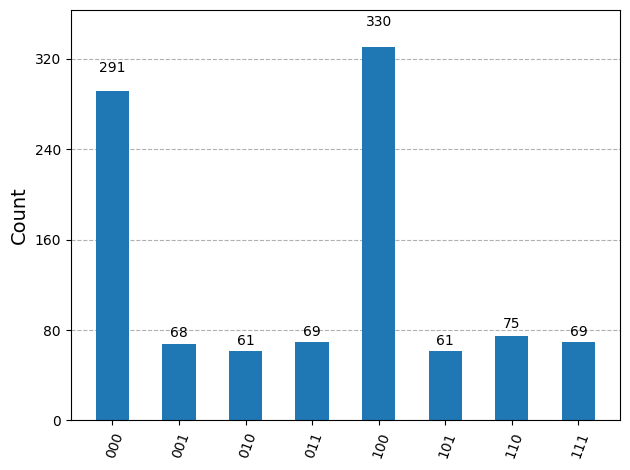

In [28]:
T = "10010111"
P = "100"

# L'algoritmo funziona solo se |T| è potenza di 2
if not (len(T) & (len(T) - 1) == 0):
  print("Errore: |T| deve essere una potenza di 2")

N = len(T)
M = len(P)
n = int(np.ceil(np.log2(N)))
# Servono N/2 ancilla qubits per il fan-out, M-1 per andTree, più 1 dedicato per il phase kickback
a = max(N // 2, M - 1) + 1

reg_K = QuantumRegister(n, name="k") # registro indice
reg_T = QuantumRegister(N, name="t") # registro stringa
reg_P = QuantumRegister(M, name="p") # registro pattern
reg_A = QuantumRegister(a, name="a") # registro ancilla

qc = QuantumCircuit(reg_K, reg_T, reg_P, reg_A)

# Popoliamo i registri usando identità e bit-flip come indicato nel paper
for i in range(N):
  if T[i] == "1":
    qc.x(reg_T[i])
  elif T[i] == "0":
    qc.id(reg_T[i])
  else:
    print("Errore nella codifica della stringa T")

for i in range(M):
  if P[i] == "1":
    qc.x(reg_P[i])
  elif P[i] == "0":
    qc.id(reg_P[i])
  else:
    print("Errore nella codifica del pattern")

# Sovrapposizione reg_K
qc.append(QFTGate(n), range(n))

def fanout():
  fo = QuantumCircuit(1 + N // 2, name="fanout") # controllo + ancilla qubits
  fo.cx(0, 1)
  copied = 1
  while copied < (N // 2):
    for i in range(copied):
      if (i + copied) < (N // 2):
        fo.cx(1 + i, copied + 1 + i)
    copied *= 2
  return fo.to_gate()

def cyclicShift():
  cs = QuantumCircuit(n + N + a, name="cyclicShift")
  for z in range(n):
    k = 2**z
    cs.append(fanout(), [z] + list(range(n + N, n + N + (N // 2)))) # copia k in reg_A
    # i = strati paralleli, j = blocchi, x = elementi dei blocchi (prima metà)
    for i in range(int(np.log2(N) - np.log2(k)), 0, -1): # ordine inverso perché leftward
      anc_id = 0
      for j in range(N // ((2**i) * k)):
        for x in range(j * k * (2**i), (j * (2**i) + 1) * k):
          cs.cswap(n + N + anc_id, n + x, n + x + (2**(i - 1)) * k)
          anc_id += 1
    cs.append(fanout().inverse(), [z] + list(range(n + N, n + N + (N // 2)))) # ripulisce reg_A per il giro dopo
  return cs.to_gate()

def computation():
  comp = QuantumCircuit(n + N + M + a, name="computation")
  # list(range(n+N)) per K e T, list(range(n + N + M, n + N + M + a)) per A
  comp.append(cyclicShift(), list(range(n + N)) + list(range(n + N + M, n + N + M + a)))
  for i in range(M):
    comp.cx(n + i, n + N + i) # il CNOT esegue uno XOR, il risultato va nel secondo parametro
  return comp.to_gate()

def andTree():
  at = QuantumCircuit((M * 2) - 1, name="andTree")
  queue = list(range(M))
  for result in range(M - 1): # result è l'indice di A che scorriamo
    q1 = queue.pop(0)
    q2 = queue.pop(0)
    target = M + result
    at.ccx(q1, q2, target)
    queue.append(target) # aggiungiamo l'ancilla appena calcolato in fondo
  return at.to_gate()

def oracle():
  orc = QuantumCircuit(M * 2, name="oracle")
  orc.x(range(M)) # inverte P
  orc.append(andTree(), range((M * 2) - 1)) # combina i qubit di P in un qubit a
  orc.cx((M * 2) - 2, (M * 2) - 1) # phase kickback tra penultimo e ultimo a
  # uncomputation
  orc.append(andTree().inverse(), range((M * 2) - 1))
  orc.x(range(M))
  return orc.to_gate()

def diffusion():
  diff = QuantumCircuit(n, name="diffusion")
  diff.h(range(n))
  diff.x(range(n))
  diff.h(n - 1)
  diff.mcx(list(range(n - 1)), n - 1)
  diff.h(n - 1)
  diff.x(range(n))
  diff.h(range(n))
  return diff.to_gate()

# Prepariamo l'ultimo ancilla qubit dedicato (a - 1) a |-> per il phase kickback
qc.x(reg_A[a - 1])
qc.h(reg_A[a - 1])

def grover():
  for _ in range(int(np.floor((np.pi / 4) * np.sqrt(N)))):
    qc.append(computation(), range(qc.num_qubits)) # shift + XOR
    qc.append(oracle(), reg_P[:] + reg_A[:M - 1] + [reg_A[a - 1]])
    qc.append(computation().inverse(), range(qc.num_qubits)) # XOR + shift
    qc.append(diffusion(), reg_K[:])

grover()

cr = ClassicalRegister(n, name="c")
qc.add_register(cr)

qc.measure(reg_K, cr)

simulator = AerSimulator()
qc_transpiled = transpile(qc, simulator)
result = simulator.run(qc_transpiled, shots=1024).result()
counts = result.get_counts()

print("Conteggi:", counts)
plot_histogram(counts)